In [40]:
import os
import sys
import json
import glob
import pandas as pd

In [9]:
experiments = glob.glob("/workspace/paper_runs/*")

In [21]:
keys = [
    "experiment", "hard_mse", "hard_lpips", "hard_rfid", "active_codes", "calibration_best_hard_mse", 
    "dead_codes", "code_utilization", "hard_perplexity", "calibration_baseline_hard_mse", 
]

In [39]:
results = []
for experiment in experiments:
    result_path = os.path.join(experiment, "result.json")
    with open(result_path, 'r') as f:
        result = json.load(f)
        
    tmp = {}
    for key in keys:
        tmp[key] = result.get(key, None)
    results.append(tmp)

df = pd.DataFrame(results)

rename_map = {
    "experiment": "Method",
    "hard_mse": "MSE",
    "hard_lpips": "LPIPS",
    "hard_rfid": "rFID",
    "active_codes": "Active Codes",
    "dead_codes": "Dead Codes",
    "code_utilization": "Utilization",
    "hard_perplexity": "PPL",
    "calibration_baseline_hard_mse": "Before Calibration MSE",
    "calibration_best_hard_mse": "After Calibration MSE",
}

df = df.rename(columns=rename_map)

paper_columns = [
    "Method",
    "MSE",
    "LPIPS",
    "rFID",
    "PPL",
    "Active Codes",
    "Dead Codes",
    "Utilization",
    "Before Calibration MSE",
    "After Calibration MSE",
]

df = df[paper_columns]
df

,Method,MSE,LPIPS,rFID,PPL,Active Codes,Dead Codes,Utilization,Before Calibration MSE,After Calibration MSE
0,arvq_16x16_q3_k1024_d64,0.008340,0.026812,5.648302,NaN,NaN,NaN,NaN,0.009523,0.008360
1,fsq_16x16_k1000_d64,0.024510,0.145077,36.073819,660.297502,1000.0,0.0,1.000000,0.026305,0.024612
2,vqema_16x16_k1024_d64,0.023234,0.127238,31.813356,635.755225,886.0,138.0,0.865234,0.024347,0.023350
3,vq_16x16_k1024_d64,0.026693,0.155818,31.341220,142.447501,181.0,843.0,0.176758,0.031506,0.026772
4,avq_8x8_k1024_d64,0.051124,0.314932,68.951267,972.421031,1024.0,0.0,1.000000,0.066978,0.051081
5,avq_16x16_k1024_d128,0.030507,0.123807,27.421868,1005.963234,1024.0,0.0,1.000000,0.054346,0.030542
6,avq_16x16_k512_d64,0.034079,0.138228,31.348549,502.609574,512.0,0.0,1.000000,0.057868,0.034092
7,avq_16x16_k1024_d64,0.030563,0.117834,28.266000,997.215425,1024.0,0.0,1.000000,0.053901,0.030633


In [38]:
for experiment in experiments:
    result_path = os.path.join(experiment, "result.json")
    with open(result_path, 'r') as f:
        result = json.load(f)

    if result["method"] == "arvq":
        break

for key in result:
    if key in {"phase1_history", "phase2_history"}:
        continue
    else:
        print(f"{key}: {result[key]}")

experiment: arvq_16x16_q3_k1024_d64
method: arvq
hard_mse: 0.008340174953142801
stage_0_hard_perplexity: 1018.4929600354202
stage_0_active_codes: 1024
stage_0_dead_codes: 0
stage_0_code_utilization: 1.0
stage_0_local_entropy: 2.038502077607647
stage_0_normalized_local_entropy: 0.2940936838206401
stage_0_mean_max_probability: 0.4502574855682949
stage_1_hard_perplexity: 1020.457357814758
stage_1_active_codes: 1024
stage_1_dead_codes: 0
stage_1_code_utilization: 1.0
stage_1_local_entropy: 2.509912404356164
stage_1_normalized_local_entropy: 0.36210381788303325
stage_1_mean_max_probability: 0.3813721173353144
stage_2_hard_perplexity: 1021.6007158813082
stage_2_active_codes: 1024
stage_2_dead_codes: 0
stage_2_code_utilization: 1.0
stage_2_local_entropy: 3.181919774463274
stage_2_normalized_local_entropy: 0.45905398791246943
stage_2_mean_max_probability: 0.296053767808144
mean_normalized_local_entropy: 0.3717504965387142
mean_max_probability: 0.37589445690391776
num_images: 10000
hard_lpips: 

In [41]:
sys.path.insert(0, "/workspace/AVQ")

%load_ext autoreload
%autoreload 2

In [42]:
from avq.dataset import build_tiny_imagenet_loaders

In [45]:
TINY_IMAGENET_ROOT = "/tmp/data/tiny-imagenet-200"
_, _, val_loader, class_to_idx, idx_to_label = build_tiny_imagenet_loaders(
    root_directory=TINY_IMAGENET_ROOT,
    batch_size=64,
    num_workers=4,
    image_size=64,
    seed=15,
    drop_last_train=True,
)

Tiny ImageNet data loaded
Root: /tmp/data/tiny-imagenet-200
Number of classes: 200
Training images: 95,000
Training-evaluation images: 5,000
Validation images: 10,000
Training batches: 1,484
Validation batches: 157


In [46]:
idx_to_label

{0: 'goldfish, Carassius auratus',
 1: 'European fire salamander, Salamandra salamandra',
 2: 'bullfrog, Rana catesbeiana',
 3: 'tailed frog, bell toad, ribbed toad, tailed toad, Ascaphus trui',
 4: 'American alligator, Alligator mississipiensis',
 5: 'boa constrictor, Constrictor constrictor',
 6: 'trilobite',
 7: 'scorpion',
 8: 'black widow, Latrodectus mactans',
 9: 'tarantula',
 10: 'centipede',
 11: 'goose',
 12: 'koala, koala bear, kangaroo bear, native bear, Phascolarctos cinereus',
 13: 'jellyfish',
 14: 'brain coral',
 15: 'snail',
 16: 'slug',
 17: 'sea slug, nudibranch',
 18: 'American lobster, Northern lobster, Maine lobster, Homarus americanus',
 19: 'spiny lobster, langouste, rock lobster, crawfish, crayfish, sea crawfish',
 20: 'black stork, Ciconia nigra',
 21: 'king penguin, Aptenodytes patagonica',
 22: 'albatross, mollymawk',
 23: 'dugong, Dugong dugon',
 24: 'Chihuahua',
 25: 'Yorkshire terrier',
 26: 'golden retriever',
 27: 'Labrador retriever',
 28: 'German shep

In [52]:
import torch
from torchvision import transforms
from avq.dataset import TinyImageNetValidationDataset

In [53]:
normalize = transforms.Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
evaluation_transform = transforms.Compose(
        [
            transforms.Resize(
                (64, 64),
                interpolation=transforms.InterpolationMode.BICUBIC,
            ),
            transforms.ToTensor(),
            normalize,
        ]
    )

In [54]:
val_dataset = TinyImageNetValidationDataset(
        val_directory="/tmp/data/tiny-imagenet-200/val",
        class_to_idx=class_to_idx,
        transform=evaluation_transform,
    )

In [55]:
import random
from collections import defaultdict

In [56]:
VIS_SEED = 42
rng = random.Random(VIS_SEED)

In [57]:
indices_by_label = defaultdict(list)

In [229]:
selected_label_ids = [
        # 185, # mushroom
    # 184, # bell pepper
    # 150, # sombrero
    198,    # seashore
    26,   # golden retriever
    44,   # monarch butterfly
    57,   # African elephant
    92,   # computer keyboard
    # 153,  # sports car
    # 145, # School bus
    # 71, # Light house
    66, # barn
    # 126, # pipe organ
    # 81, # bullet train
    # 109, # hour glass
    # 160, # teapot
    157,  # suspension bridge
    191,  # pizza
]

In [230]:
# for idx in range(len(val_dataset)):
#     _, label = val_dataset[idx]
#     indices_by_label[label].append(idx)

In [231]:
# visual_indices = {
#     label: rng.choice(indices_by_label[label])
#     for label in selected_label_ids
# }

In [232]:
# indices_by_label

In [227]:
visual_indices = {
    26: 242, # dog
    198: 1457, # seashore
    44: 9379, # butterfly
    57: 855, # elephant
    92: 825, # keyboard
    66: 6675, # barn
    71: 4977, # lighthouse
    191: 2862, # pizza
}

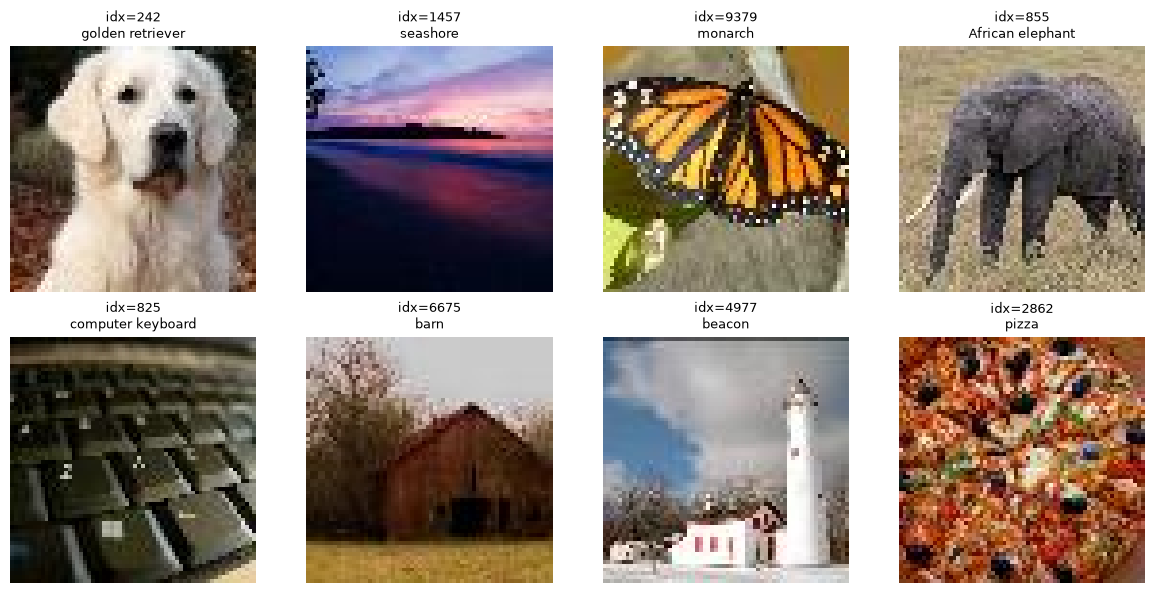

In [228]:
import matplotlib.pyplot as plt

def denormalize_image(x):
    # [-1, 1] -> [0, 1]
    return ((x + 1.0) / 2.0).clamp(0, 1)


fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for ax, (label, idx) in zip(axes.flat, visual_indices.items()):
    image, actual_label = val_dataset[idx]

    image = denormalize_image(image)
    image = image.permute(1, 2, 0).cpu().numpy()

    ax.imshow(image)
    ax.set_title(
        f"idx={idx}\n"
        f"{idx_to_label[actual_label].split(',')[0]}",
        fontsize=9,
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [219]:
def plot_class_candidates(
    dataset,
    label,
    indices_by_label,
    idx_to_label,
    n=12,
    seed=6,
):
    candidates = indices_by_label[label]

    rng = random.Random(seed + label)
    selected = rng.sample(candidates, min(n, len(candidates)))

    ncols = 4
    nrows = (len(selected) + ncols - 1) // ncols

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(12, 3 * nrows),
    )

    axes = axes.flatten()

    for ax, idx in zip(axes, selected):
        image, actual_label = dataset[idx]

        image = denormalize_image(image)
        image = image.permute(1, 2, 0).cpu().numpy()

        ax.imshow(image)
        ax.set_title(f"index = {idx}")
        ax.axis("off")

    # Hide unused axes
    for ax in axes[len(selected):]:
        ax.axis("off")

    class_name = idx_to_label[label].split(",")[0]

    fig.suptitle(
        f"Label {label}: {class_name}",
        fontsize=14,
    )

    plt.tight_layout()
    plt.show()

    return selected

In [233]:
# for label in selected_label_ids:
#     plot_class_candidates(
#         val_dataset,
#         label=label,
#         indices_by_label=indices_by_label,
#         idx_to_label=idx_to_label,
#         n=12,
#         seed=42,
#     )
    

In [ ]:
@torch.no_grad()
def visual_inspection(model, loader, device, n=8, temperature=0.1, soft_weight=0.1):
    """
    Generates a visual comparison of original images alongside their soft and hard reconstructions.
    """
    model.eval()

    imgs, _ = next(iter(loader))
    imgs = imgs[:n].to(device)

    # Images from the loader are already normalized to [-1, 1].
    outputs = model(
        imgs, temperature=temperature, 
        soft_weight=soft_weight, return_separate_reconstructions=True,
    )

    reconstruction_soft = outputs["reconstruction_soft"]
    reconstruction_hard = outputs["reconstruction_hard"]

    # Convert original and reconstructed images from [-1, 1] to [0, 1].
    imgs_display = ((imgs + 1.0) / 2.0).clamp(0.0, 1.0)
    reconstruction_soft_display = ((reconstruction_soft + 1.0) / 2.0).clamp(0.0, 1.0)
    reconstruction_hard_display = ((reconstruction_hard + 1.0) / 2.0).clamp(0.0, 1.0)

    fig, axes = plt.subplots(3, n, figsize=(2 * n, 6), squeeze=False)

    for i in range(n):
        original = imgs_display[i]
        soft = reconstruction_soft_display[i]
        hard = reconstruction_hard_display[i]

        for row, image, title in [(0, original, "Original"), (1, soft, "Soft"), (2, hard, "Hard Argmax")]:
            
            cmap = "gray" if image.shape[0] == 1 else None
            vmin = 0.0 if cmap == "gray" else None
            vmax = 1.0 if cmap == "gray" else None

            axes[row, i].imshow(image_for_plot(image), cmap=cmap, vmin=vmin, vmax=vmax)
            axes[row, i].set_title(title)
            axes[row, i].axis("off")

    fig.suptitle(f"AVQ Reconstructions at Temperature = {temperature:.3f}", fontsize=14)
    plt.tight_layout()
    plt.show()

In [243]:
from pathlib import Path
import matplotlib.pyplot as plt

def denormalize_image(x):
    # [-1, 1] -> [0, 1]
    return ((x + 1.0) / 2.0).clamp(0, 1)

visual_indices = {
    26: 242, # dog
    198: 1457, # seashore
    44: 9379, # butterfly
    57: 855, # elephant
    92: 825, # keyboard
    66: 6675, # barn
    71: 4977, # lighthouse
    191: 2862, # pizza
}

from avq.config import EXPERIMENT_REGISTRY

In [263]:
baseline_order = ["original", "vq_16x16_k1024_d64", "vqema_16x16_k1024_d64", "fsq_16x16_k1000_d64", "avq_16x16_k1024_d64"]
residual_order = ["original", "avq_16x16_k1024_d64", "arvq_16x16_q3_k1024_d64"]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

experiment_dir = Path("/workspace/paper_runs/")

experiment_name = "vq_16x16_k1024_d64"
experiment = EXPERIMENT_REGISTRY[experiment_name]

model = experiment.model_cls(**experiment.model_kwargs).to(device)

In [265]:
checkpoint_dir = experiment_dir / "vq_16x16_k1024_d64" / "calibration" 
checkpoint = checkpoint_dir / "best_decoder_calibration.pt"
checkpoint

PosixPath('/workspace/paper_runs/vq_16x16_k1024_d64/calibration/best_decoder_calibration.pt')

In [262]:
state_dict.keys()


dict_keys(['phase', 'epoch', 'global_step', 'model_state_dict', 'optimizer_state_dict', 'train_hard_mse', 'val_hard_mse', 'best_val_hard_mse', 'best_epoch', 'history'])

In [268]:
def reconstruct_images(method, model, image):
    if method == "avq":
        outputs = model(
            image, 
            temperature=0.02, 
            soft_weight=0.0, 
            return_separate_reconstructions=False,
        )
    
        reconstruction = outputs["reconstruction_train"]
    elif method == "arvq":
        outputs = model(image, temperature=0.02, mode="hard")
        reconstruction = outputs["reconstruction"]
    else:
        outputs = model(image)
        reconstruction = outputs["reconstruction"]

    return reconstruction

def load_model(experiment_name, checkpoint, device):
    experiment = EXPERIMENT_REGISTRY[experiment_name]
    model = experiment.model_cls(**experiment.model_kwargs).to(device)
    state_dict = torch.load(checkpoint, map_location=device, weights_only=True)
    model.load_state_dict(state_dict["model_state_dict"])
    model.eval()
    return model

def plot_original(visual_indices, val_dataset, idx_to_label):
    fig, axes = plt.subplots(1, len(visual_indices), figsize=(6, 12))
    for ax, (label, idx) in zip(axes.flat, visual_indices.items()):
        image, actual_label = val_dataset[idx]
        image = denormalize_image(image)
        image = image.permute(1, 2, 0).cpu().numpy()

        ax.imshow(image)
        ax.set_title(f"index = {idx}")
        ax.axis("off")

    plt.tight_layout()
    plt.show()

def plot_reconstruction(method, model, visual_indices, val_dataset, idx_to_label):
    fig, axes = plt.subplots(1, len(visual_indices), figsize=(6, 12))
    for ax, (label, idx) in zip(axes.flat, visual_indices.items()):
        image, actual_label = val_dataset[idx]
        reconstruction = reconstruct_images(method, model, image)
        reconstruction = denormalize_image(reconstruction)
        reconstruction = reconstruction.permute(1, 2, 0).cpu().numpy()
        ax.imshow(reconstruction)
        ax.set_title(f"{idx_to_label[actual_label].upper().split(',')[0]}", fontsize=6)
        ax.axis("off")
    plt.tight_layout()
    plt.show()


def visualize_reconstruction(
    visual_indices, 
    experiment_order, 
    experiment_dir, 
    val_dataset,
    idx_to_label,
):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    for experiment_name in experiment_order:
        if experiment_name == "original":
            plot_original(visual_indices, val_dataset, idx_to_label)
        else:
            checkpoint_dir = experiment_dir / experiment / "calibration"
            method = experiment_name.split('_')[0]
            pt_file = "best_arvq_decoder_calibration.pt" if method == "arvq" else "best_decoder_calibration.pt"
            checkpoint = checkpoint_dir / pd_file
            model = load_model(experiment_name, checkpoint, device)
            plot_reconstruction(method, model, visual_indices, val_dataset, idx_to_label)



baseline_order = ["original", "vq_16x16_k1024_d64", "vqema_16x16_k1024_d64", "fsq_16x16_k1000_d64", "avq_16x16_k1024_d64"]
residual_order = ["original", "avq_16x16_k1024_d64", "arvq_16x16_q3_k1024_d64"]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

experiment_dir = Path("/workspace/paper_runs/")

In [291]:
from pathlib import Path

import matplotlib.pyplot as plt
import torch


def denormalize_image(image):
    """Convert image from [-1, 1] to [0, 1]."""
    return ((image + 1.0) / 2.0).clamp(0, 1)


@torch.inference_mode()
def reconstruct_image(method, model, image, device, temperature=0.02):
    """
    Reconstruct one image using hard discrete latents.

    image:
        [C, H, W]

    returns:
        [C, H, W] on CPU
    """
    image = image.unsqueeze(0).to(device)  # [1, C, H, W]

    if method == "avq":
        # Explicit hard AVQ inference
        encoded = model.encoder(image)

        quantizer_outputs = model.quantizer(
            encoded,
            temperature=temperature,
        )

        hard_quantized = quantizer_outputs["hard_quantized"]

        reconstruction = model.decoder(hard_quantized)

    elif method == "arvq":
        # ARVQ already supports an explicit hard mode
        outputs = model(
            image,
            temperature=temperature,
            mode="hard",
        )

        reconstruction = outputs["reconstruction"]

    else:
        # VQ / VQ-EMA / FSQ use hard discrete values
        # in their standard forward pass
        outputs = model(image)

        reconstruction = outputs["reconstruction"]

    return reconstruction.squeeze(0).cpu()


def load_model(experiment_name, checkpoint, device):
    experiment = EXPERIMENT_REGISTRY[experiment_name]

    model = experiment.model_cls(
        **experiment.model_kwargs
    ).to(device)

    state_dict = torch.load(
        checkpoint,
        map_location=device,
        weights_only=True,
    )

    model.load_state_dict(
        state_dict["model_state_dict"]
    )

    model.eval()

    return model


def get_checkpoint_path(
    experiment_name,
    experiment_dir,
):
    method = experiment_name.split("_")[0]

    checkpoint_dir = (
        experiment_dir
        / experiment_name
        / "calibration"
    )

    if method == "arvq":
        pt_file = "best_arvq_decoder_calibration.pt"
    else:
        pt_file = "best_decoder_calibration.pt"

    return checkpoint_dir / pt_file


def plot_reconstruction_grid(
    experiment_order,
    row_names,
    visual_indices,
    experiment_dir,
    val_dataset,
    idx_to_label,
    figsize=None,
    save_path=None,
):
    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

    nrows = len(experiment_order)
    ncols = len(visual_indices)

    if figsize is None:
        figsize = (12, 1.8 * nrows)

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=figsize,
        squeeze=False,
    )

    visual_items = list(visual_indices.items())

    # Column titles
    for col, (_, idx) in enumerate(visual_items):
        _, actual_label = val_dataset[idx]

        class_name = display_names[actual_label]

        axes[0, col].set_title(
            class_name,
            fontsize=8,
            fontweight="bold",
        )

    # Rows
    for row, experiment_name in enumerate(experiment_order):

        if experiment_name == "original":

            for col, (_, idx) in enumerate(visual_items):
                image, _ = val_dataset[idx]

                display_image = denormalize_image(image)
                display_image = (
                    display_image
                    .permute(1, 2, 0)
                    .cpu()
                    .numpy()
                )

                axes[row, col].imshow(display_image)

        else:
            method = experiment_name.split("_")[0]

            checkpoint = get_checkpoint_path(
                experiment_name,
                experiment_dir,
            )

            print(
                f"Loading {experiment_name}: "
                f"{checkpoint}"
            )

            model = load_model(
                experiment_name,
                checkpoint,
                device,
            )

            for col, (_, idx) in enumerate(visual_items):
                image, _ = val_dataset[idx]

                reconstruction = reconstruct_image(
                    method,
                    model,
                    image,
                    device,
                    temperature=0.02,
                )

                display_image = denormalize_image(
                    reconstruction
                )

                display_image = (
                    display_image
                    .permute(1, 2, 0)
                    .numpy()
                )

                axes[row, col].imshow(display_image)

            del model

            if device.type == "cuda":
                torch.cuda.empty_cache()

        # Hide ticks/spines but DO NOT call axis("off")
        for col in range(ncols):
            ax = axes[row, col]

            ax.set_xticks([])
            ax.set_yticks([])

            for spine in ax.spines.values():
                spine.set_visible(False)

        # Method name on left
        axes[row, 0].set_ylabel(
            row_names[row],
            fontsize=10,
            fontweight="bold",
            rotation=0,
            labelpad=35,
            va="center",
        )

    plt.tight_layout()

    if save_path is not None:
        plt.savefig(
            save_path,
            dpi=300,
            bbox_inches="tight",
        )

    plt.show()

In [292]:
visual_indices = {
    26: 242,     # golden retriever
    198: 1457,   # seashore
    44: 9379,    # monarch butterfly
    57: 855,     # African elephant
    92: 825,     # computer keyboard
    66: 6675,    # barn
    71: 4977,    # lighthouse
    191: 2862,   # pizza
}

experiment_dir = Path("/workspace/paper_runs/")

display_names = {
    26: "Golden Retriever",
    198: "Seashore",
    44: "Monarch Butterfly",
    57: "African Elephant",
    92: "Computer Keyboard",
    66: "Barn",
    71: "Lighthouse",
    191: "Pizza",
}

Loading vq_16x16_k1024_d64: /workspace/paper_runs/vq_16x16_k1024_d64/calibration/best_decoder_calibration.pt
Loading vqema_16x16_k1024_d64: /workspace/paper_runs/vqema_16x16_k1024_d64/calibration/best_decoder_calibration.pt
Loading fsq_16x16_k1000_d64: /workspace/paper_runs/fsq_16x16_k1000_d64/calibration/best_decoder_calibration.pt
Loading avq_16x16_k1024_d64: /workspace/paper_runs/avq_16x16_k1024_d64/calibration/best_decoder_calibration.pt


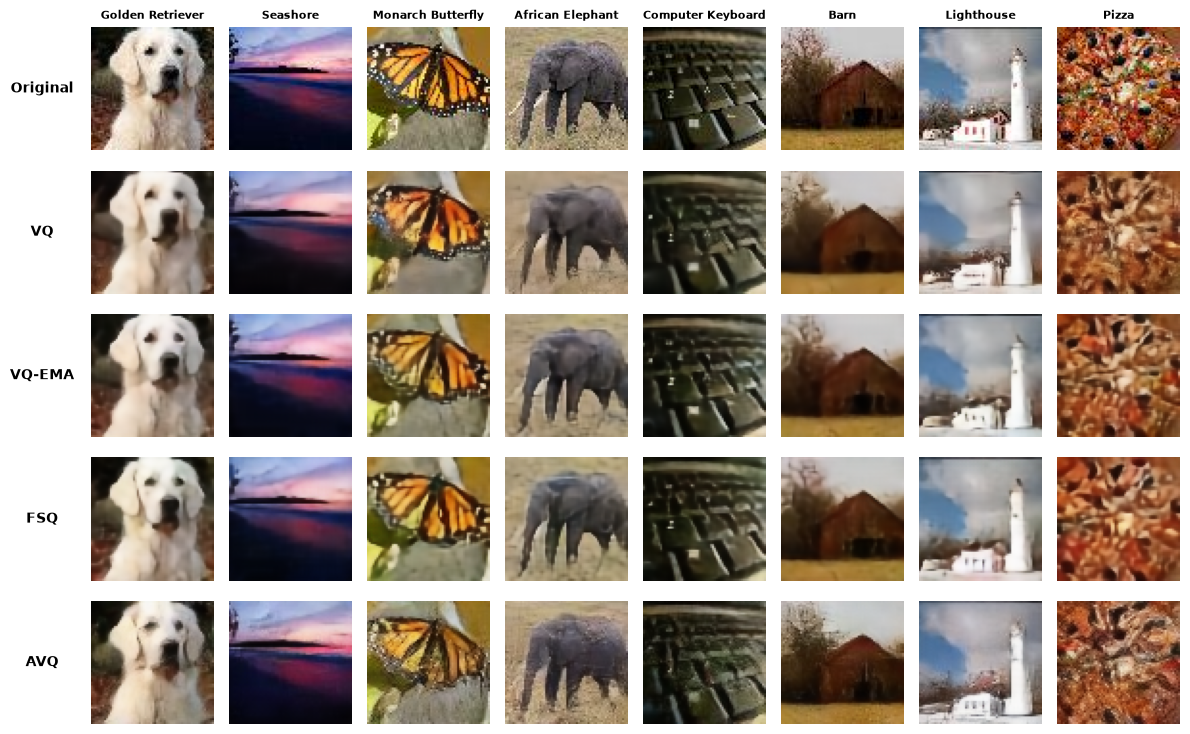

In [293]:
baseline_order = [
    "original",
    "vq_16x16_k1024_d64",
    "vqema_16x16_k1024_d64",
    "fsq_16x16_k1000_d64",
    "avq_16x16_k1024_d64",
]

baseline_row_names = [
    "Original",
    "VQ",
    "VQ-EMA",
    "FSQ",
    "AVQ",
]

plot_reconstruction_grid(
    experiment_order=baseline_order,
    row_names=baseline_row_names,
    visual_indices=visual_indices,
    experiment_dir=experiment_dir,
    val_dataset=val_dataset,
    idx_to_label=idx_to_label,
    figsize=(12, 7.5),
    save_path="baseline_reconstructions.pdf",
)

Loading avq_16x16_k1024_d64: /workspace/paper_runs/avq_16x16_k1024_d64/calibration/best_decoder_calibration.pt
Loading arvq_16x16_q3_k1024_d64: /workspace/paper_runs/arvq_16x16_q3_k1024_d64/calibration/best_arvq_decoder_calibration.pt


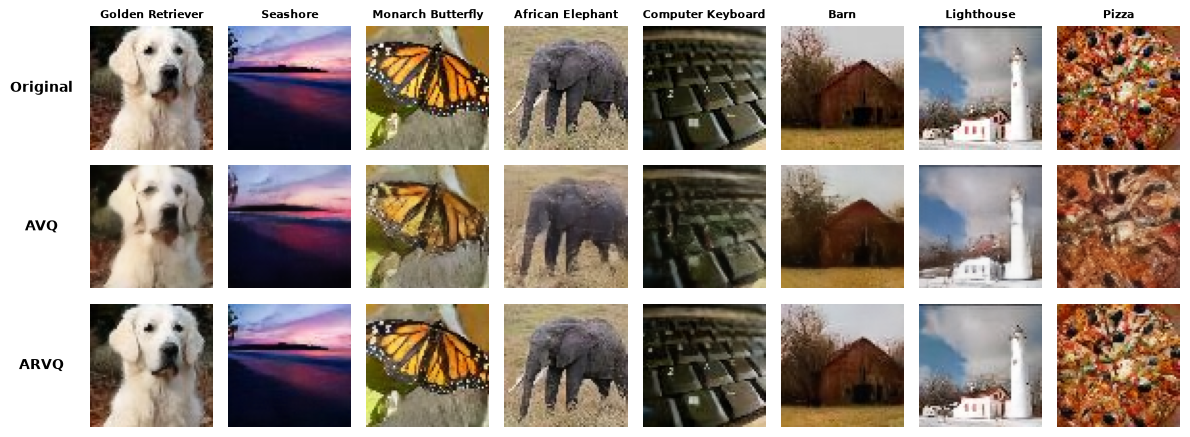

In [294]:
residual_order = [
    "original",
    "avq_16x16_k1024_d64",
    "arvq_16x16_q3_k1024_d64",
]

residual_row_names = [
    "Original",
    "AVQ",
    "ARVQ",
]

plot_reconstruction_grid(
    experiment_order=residual_order,
    row_names=residual_row_names,
    visual_indices=visual_indices,
    experiment_dir=experiment_dir,
    val_dataset=val_dataset,
    idx_to_label=idx_to_label,
    figsize=(12, 4.5),
    save_path="arvq_reconstructions.pdf",
)